# Object Detection: Finding Fish and Other Aquarium Animals
**EGR 444: Advanced AI/ML for Engineering Applications**

In this lesson, we will inspect labeled images, adapt a pretrained detector, evaluate its mistakes, and decide which evaluation metrics answer our question. By the end, you should be able to explain what the model receives, what it predicts, how it learns, and how you would decide whether it is useful for a given task.

We will work with **Aquarium Combined v2**, provided by Roboflow under CC BY 4.0. It includes fish and six other animal categories and their bounding boxes. We preserve the provided train/validation/test split. Your `utils/get_data.py` downloads the source files; `utils/COCO_to_YOLO.py` converts them into `data/aquarium_clean/`.

**Local setup:** use Python 3.12, install the requirements, and select that environment as your notebook kernel. Set `LOCAL_ROOT` below to the folder containing your project directory.

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd().resolve()

# If we started inside notebooks/, move up to the repo root.
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Use the repo root for relative paths and imports.
os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print(f"Repository: {ROOT}")

Repository: /Users/meganchiovaro/Documents/github/object-detection-lesson


In [2]:
# import standard libraries and third-party packages
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from IPython.display import display
from ultralytics import YOLO
import subprocess
import hashlib
import json

# import utility functions for formatting and reading labels
from utils.read_labels import read_labels
from PIL import Image
from utils.COCO_to_YOLO import CLASSES

torch.set_num_threads(2)  # limit CPU overhead by PyTorch
DEVICE = 0 if torch.cuda.is_available() else "cpu"

# confirm the environment and paths are set correctly
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__, "device:", DEVICE)

Python: 3.12.4 PyTorch: 2.2.2 device: cpu


In [ ]:
# specify where our data are
DATA_DIR = ROOT / "data" / "aquarium_clean"

# create a unique experiment name
EXPERIMENT_NAME = "my_first_detector"

# keep everything from a single experiment together
RUN_DIR = ROOT / "outputs" / EXPERIMENT_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_DIR = RUN_DIR / "training"
TRAIN_DIR.mkdir(parents=True, exist_ok=True)
VAL_DIR = RUN_DIR / "validation"
VAL_DIR.mkdir(parents=True, exist_ok=True)
TEST_DIR = RUN_DIR / "testing"
TEST_DIR.mkdir(parents=True, exist_ok=True)

# confirm the environment and paths are set correctly
print("Saving results to:", RUN_DIR)

Saving results to: /Users/meganchiovaro/Documents/github/object-detection-lesson/outputs/my_first_detector


### Prepare the data if needed

The downloaded folders go directly under `data/aquarium_raw/`: `train`, `valid`, and `test`. 

This cell uses the two existing data preparation scripts (`utils/get_data.py` and `utils/COCO_to_YOLO.py`) only when the prepared data is missing. If all three prepared image/label folders already contain files, it leaves them alone. The prepared data go under `data/aquarium_clean/`: `train`, `valid`, and `test`. 

In [4]:
# check whether all three splits contain prepared images and labels
prepared = all(
    any((DATA_DIR / "images" / split).glob("*.jpg"))
    and any((DATA_DIR / "labels" / split).glob("*.txt"))
    for split in ["train", "val", "test"]
)

if not prepared:
    # check whether the original dataset has already been downloaded
    raw_dir = ROOT / "data" / "aquarium_raw"
    annotation_files = [
        raw_dir / split / "_annotations.coco.json"
        for split in ["train", "valid", "test"]
    ]

    if not all(path.is_file() for path in annotation_files):
        print("Downloading the original dataset...")
        subprocess.check_call([
            sys.executable,
            str(ROOT / "utils" / "get_data.py"),
        ])

    # convert COCO annotations into YOLO labels and copy the images
    print("Preparing images and labels...")
    subprocess.check_call([
        sys.executable,
        str(ROOT / "utils" / "COCO_to_YOLO.py"),
    ])

else:
    print("Prepared data already exists. Skipping preparation.")

print("Data folder:", DATA_DIR)

Prepared data already exists. Skipping preparation.
Data folder: /Users/meganchiovaro/Documents/github/object-detection-lesson/data/aquarium_clean


## 1. What output do we need?

| Task | Example question | Output |
|---|---|---|
| Classification | Does this image contain a fish? | Image label(s) |
| Detection | Where is each fish? | Boxes and a class per object |
| Semantic segmentation | Which pixels are fish? | A class per pixel |
| Instance segmentation | Which pixels belong to each individual? | A mask per object |

We will focus on **detection** for this lesson. A box gives location; the class says which annotation category the object belongs to.

The following cell converts the YOLO boxes back to pixel corners so we can take a look at an example image.

Class IDs and names: {0: 'fish', 1: 'jellyfish', 2: 'penguin', 3: 'puffin', 4: 'shark', 5: 'starfish', 6: 'stingray'}


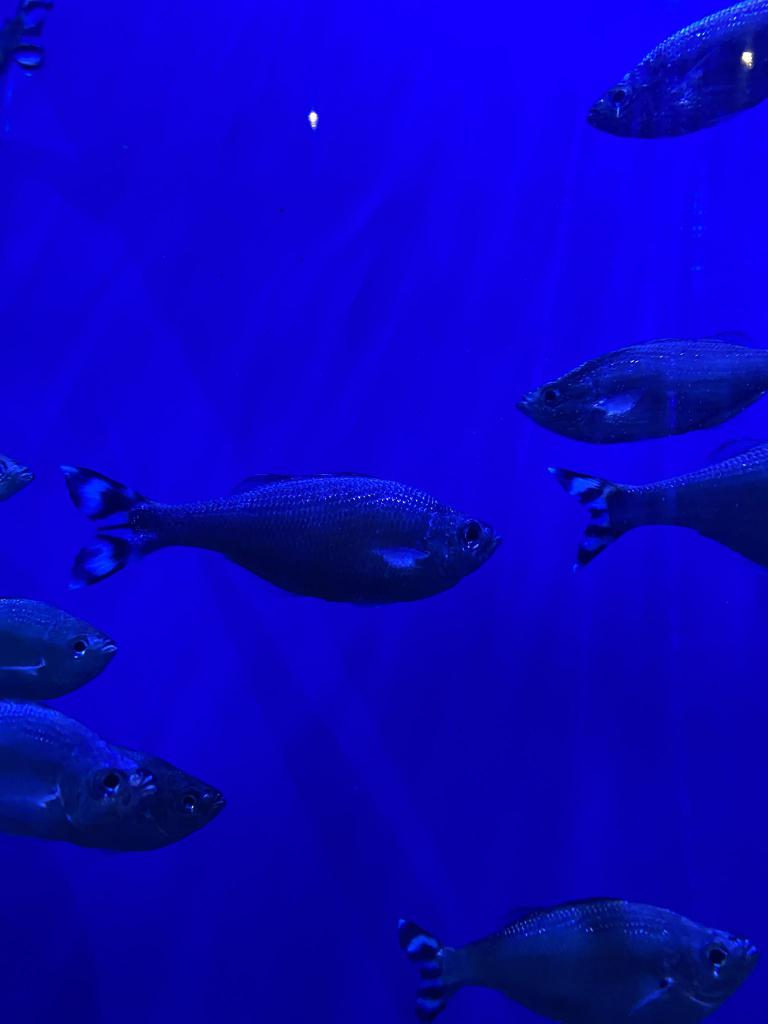

In [5]:
print(f"Class IDs and names: {dict(enumerate(CLASSES))}")
train_paths = sorted((DATA_DIR / "images" / "train").glob("*.jpg"))
val_paths = sorted((DATA_DIR / "images" / "val").glob("*.jpg"))
test_paths = sorted((DATA_DIR / "images" / "test").glob("*.jpg"))

# choose an image with several labeled fish so we can take a look
example = train_paths[0]
for path in train_paths:
    boxes = read_labels(path)
    # between 3 and 12 boxes, and at least one box is of class 0
    if 3 <= len(boxes) <= 12 and any(box[0] == 0 for box in boxes):
        example = path
        break

display(Image.open(example))

**Before running the next cell:** where would you put the boxes? Would you annotate a partially hidden fish? What rule would you want every annotator to follow?

Number of ground truth boxes in image: 8


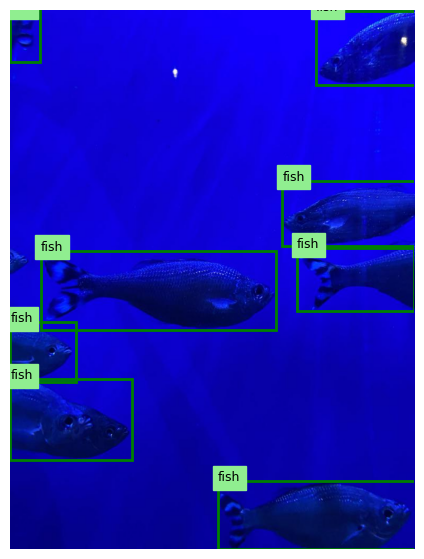

In [6]:
def show_boxes(image_path, predictions=None):
    """Show green bounding boxes (and orange predicted boxes, if provided).

    Ground truth box rows have five values (label, x1, y1, x2, y2); 
    prediction rows have six because they also include a confidence score
    (label, score, x1, y1, x2, y2). Both use pixel-corner coordinates
    because of read_labels().
    """
    _, ax = plt.subplots(figsize=(11, 7))
    ax.imshow(Image.open(image_path).convert("RGB"))

    num_boxes = len(read_labels(image_path))
    print(f"Number of ground truth boxes in image: {num_boxes}")

    # draw ground truth boxes in green
    for class_id, x1, y1, x2, y2 in read_labels(image_path):
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor="green", linewidth=2))
        ax.text(x1, y1, CLASSES[int(class_id)], fontsize=9,
                backgroundcolor="lightgreen", clip_on=True)

    # draw predicted boxes in orange, if provided
    if predictions is not None:
        for class_id, score, x1, y1, x2, y2 in predictions:
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                   fill=False, edgecolor="darkorange", linewidth=2))
            ax.text(x1, y1, f"{CLASSES[int(class_id)]} ({score:.2f})", fontsize=9,
                                clip_on=True, bbox=dict(facecolor="lightcoral", alpha=0.7, edgecolor="none"))
    ax.axis("off")
    plt.show()


show_boxes(example)

## 2. Read the labels before training

A YOLO detection label file has one row per object:

`class_id  x_center  y_center  width  height`

Coordinates are fractions of the image dimensions. The image below is a real example. Images can have different numbers of objects, so the target is not one fixed-length vector for every image.

In [7]:
label_file = DATA_DIR / "labels" / "train" / f"{example.stem}.txt"
print("Original YOLO rows [class, center_x, center_y, width, height]:")
print(label_file.read_text())
print("Converted pixel-corner rows: [class, xmin, ymin, xmax, ymax]:")
print(read_labels(example)[:5].round(2))

Original YOLO rows [class, center_x, center_y, width, height]:
0 0.15039062 0.75927734 0.30078125 0.14941406
0 0.36588542 0.51953125 0.58072917 0.14648438
0 0.87825521 0.06982422 0.24348958 0.13769531
0 0.83658854 0.37695312 0.32682292 0.12109375
0 0.85416667 0.49951172 0.28906250 0.11621094
0 0.08072917 0.63476562 0.16145833 0.11132812
0 0.03710938 0.04833984 0.07421875 0.09667969
0 0.75716146 0.93652344 0.48567708 0.12500000
Converted pixel-corner rows: [class, xmin, ymin, xmax, ymax]:
[[          0          -0         701         231         854]
 [          0          58         457         504         607]
 [          0         581           1         768         142]
 [          0         517         324         768         448]
 [          0         545         452         767         571]]


## 3. Check the dataset and the split

This data check verifies image/label pairs, class IDs, counts per class, and exact image duplication across splits. 

,split,images
0,train,448
1,val,127
2,test,63


Labeled object counts:


,train,val,test
fish,1961,459,249
jellyfish,385,155,154
penguin,330,104,82
puffin,175,74,35
shark,259,57,36
starfish,78,27,11
stingray,136,33,15


Labeled object counts in percentages:


,train,val,test
fish,59.0,50.5,42.8
jellyfish,11.6,17.1,26.5
penguin,9.9,11.4,14.1
puffin,5.3,8.1,6.0
shark,7.8,6.3,6.2
starfish,2.3,3.0,1.9
stingray,4.1,3.6,2.6


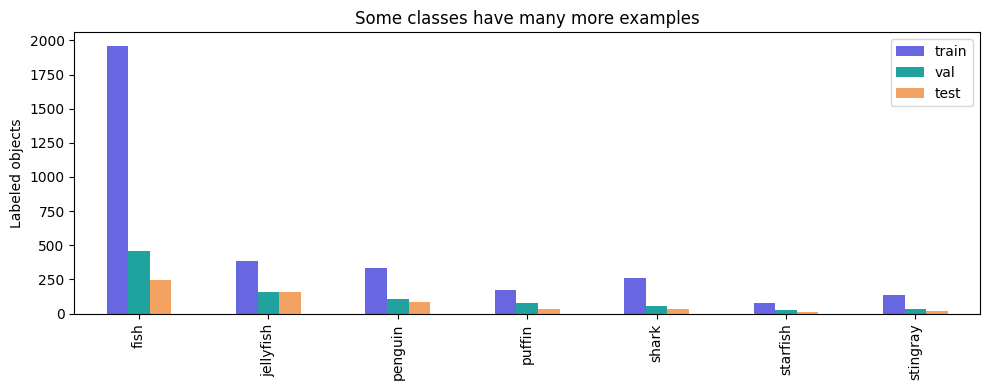

In [8]:
# inspect split sizes and check that identical image bytes do not cross splits
seen_images = {}
split_rows = []

for split in ["train", "val", "test"]:
    paths = sorted((DATA_DIR / "images" / split).glob("*.jpg"))
    for path in paths:
        fingerprint = hashlib.sha256(path.read_bytes()).hexdigest()

        # if the image has been seen before, check if it's in a different split
        if fingerprint in seen_images and seen_images[fingerprint] != split:
            raise ValueError(f"Identical image found in different splits: {path.name}")
        seen_images[fingerprint] = split

    # create a summary row for the current split
    split_rows.append({"split": split, "images": len(paths)})
display(pd.DataFrame(split_rows))

# count labeled objects in train, validation and test
counts = pd.DataFrame(0, index=CLASSES, columns=["train", "val", "test"])
for split, paths in [("train", train_paths), ("val", val_paths), ("test", test_paths)]:
    for path in paths:
        for class_id, *_ in read_labels(path):
            counts.loc[CLASSES[int(class_id)], split] += 1

# convert the counts to percentages with one decimal
counts_pct = (counts.div(counts.sum(axis=0), axis=1) * 100).round(1)

print("Labeled object counts:")
display(counts)
print("Labeled object counts in percentages:")
display(counts_pct)

counts.plot.bar(figsize=(10, 4), color=["#6866E1", "#20A39E", "#F4A261"])
plt.ylabel("Labeled objects")
plt.title("Some classes have many more examples")
plt.tight_layout()
plt.show()

**Discuss:** Which class may be hardest to evaluate reliably? A class with very few validation examples can have a jumpy score. Overall averages can hide that.

**Reminder:** For video data, we would usually group by recording or site before splitting. Randomly distributing neighboring frames can make validation look easier than the intended deployment.

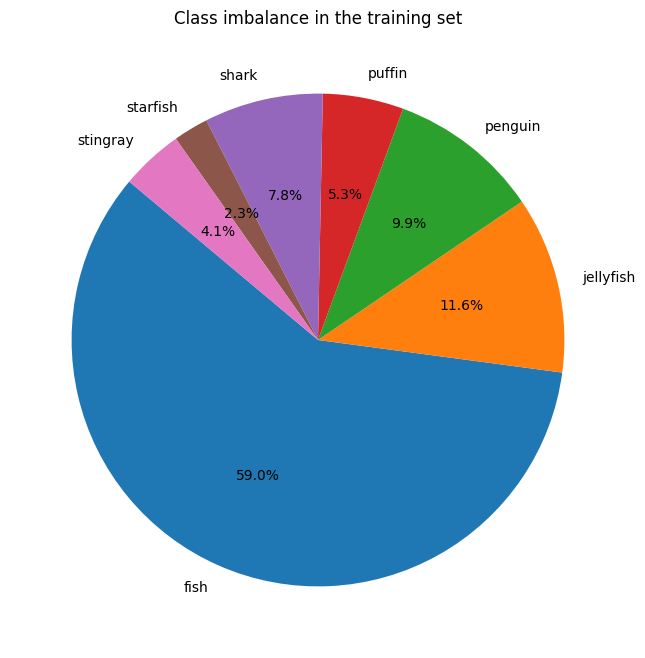

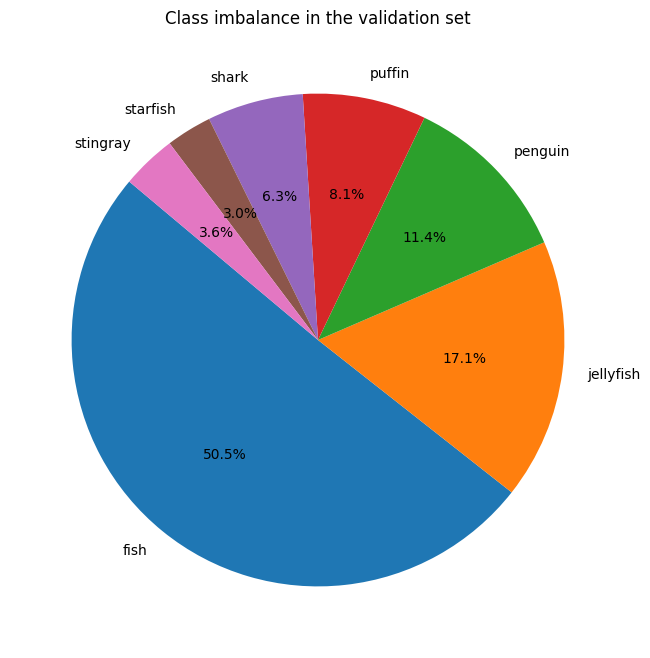

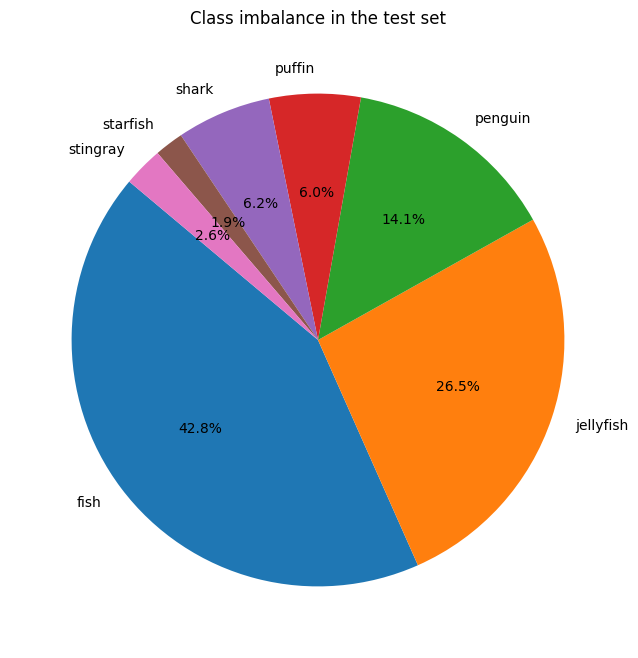

In [9]:
# inspect class imbalance in the dataset with pie charts
counts_pct = (counts.div(counts.sum(axis=0), axis=1) * 100).round(1)

plt.figure(figsize=(8, 8))
plt.pie(counts_pct["train"], labels=counts_pct.index, autopct='%1.1f%%', startangle=140)
plt.title("Class imbalance in the training set")
plt.show()

plt.figure(figsize=(8, 8))
plt.pie(counts_pct["val"], labels=counts_pct.index, autopct='%1.1f%%', startangle=140)
plt.title("Class imbalance in the validation set")
plt.show()

plt.figure(figsize=(8, 8))
plt.pie(counts_pct["test"], labels=counts_pct.index, autopct='%1.1f%%', startangle=140)
plt.title("Class imbalance in the test set")
plt.show()

## 4. Choose a manageable model

We use **YOLOv8 nano** so the first training run stays small and the detector matches the family introduced in the slides. It is a teaching choice, not a claim that it is the newest or universally best detector.

Its pretrained weights learned useful visual features on COCO. Aquarium has seven different output classes. Fine-tuning adapts the prediction head and, with `freeze: null`, updates all trainable model weights.

A useful later comparison is **YOLOv8 small**. Keep the split and training recipe fixed, then compare quality, latency, and file size. We will not start with several architectures at once.

In [10]:
# Ultralytics downloads the official starting weights if this file is missing
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
starting_weights = MODEL_DIR / "yolov8n.pt"
starting_model = YOLO(str(starting_weights))

print("Pretraining classes:", len(starting_model.names))
print("Our target classes:", len(CLASSES))

# check for overlapping class names between pre-trained starting model and our target classes
print("Overlapping class names:", sorted(set(starting_model.names.values()) & set(CLASSES))) 

Pretraining classes: 80
Our target classes: 7
Overlapping class names: []


We will need to re-assign the classes in the prediction head.

## 5. Train a short baseline

The default config (`configs/train.yaml`) uses **all 448 training images, five epochs, and 320-pixel inputs**.

### Some settings should be very familiar

| Setting | What it changes | What to watch |
|---|---|---|
| `epochs` | Passes over the training set | More passes can help, stall, or overfit |
| `batch` | Images per optimizer update | Memory and number of updates per epoch |
| `lr0` | Initial learning rate | Unstable loss or learning that is slow |
| `fliplr` | Horizontal-flip probability | The transformed boxes must still fit the image |
| `mosaic` | Mixing images during augmentation | Useful variation can also change scene context |
| `freeze` | Weights held fixed | Transfer-learning choice |

`lr0` is a base learning rate. Warmup and the schedule change actual rates during training; the CSV records them. This pinned trainer uses at least 100 warmup steps when warmup is enabled, so an extremely short run can spend most of its budget warming up.

### What the new training settings do

| Setting | Meaning | Our starting value |
|---|---|---|
| `fliplr` | Probability of flipping a training image left/right. The bounding boxes flip too. | `0.5`: a 50% chance each time an image is loaded for training. |
| `mosaic` | Probability of combining several training images, usually four, into one image, with their boxes adjusted. | `0.0`: disabled. |
| `imgsz` | Target image input size. YOLO preserves the aspect ratio and adds padding as needed. | `320`: target size of 320 pixels. |
| `patience` | Number of epochs allowed without improvement in validation fitness before early stopping. | `10`: early stopping will not trigger during our five-epoch run. |
| `freeze` | Holds selected layers fixed while other layers learn. | `null`: no layers are explicitly frozen through this setting. |

**How these apply to our dataset:**

- **Horizontal flipping** gives the model examples of animals facing either direction.
- **Mosaic** adds variation in object sizes and arrangements, but, can create unrealistic scenes.
- **Larger inputs** may preserve details needed to detect small fish, while requiring more memory and computation. Changing `imgsz` does not modify the original image files.
- **Patience** is useful for longer runs because it can stop training when validation performance stops improving.
- **Freezing layers** preserves some pretrained weights while the remaining layers adapt. For example, `freeze: 10` freezes the first 10 indexed model layers; these may be larger blocks containing several operations.

Remember: For a controlled experiment, change one setting at a time and compare both validation metrics and example predictions.

For a longer run, edit epochs and imgsz in the YAML file.

In [11]:
# load the existing training settings
config_file_name = "train.yaml"
config_file = ROOT / "configs" / config_file_name
config = yaml.safe_load(config_file.read_text())

# tell YOLO where the dataset is and what each class ID means
dataset_config = {
    "path": str(DATA_DIR.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": dict(enumerate(CLASSES)),
}

# save the dataset settings for YOLO to read
dataset_yaml = TRAIN_DIR / "data.yaml"
dataset_yaml.write_text(yaml.safe_dump(dataset_config, sort_keys=False))

print("Training settings:")
print(config)

print("Dataset settings:")
print(dataset_yaml.read_text())

Training settings:
{'model': 'models/yolov8n.pt', 'epochs': 5, 'imgsz': 320, 'batch': 8, 'lr0': 0.001, 'optimizer': 'AdamW', 'seed': 444, 'mosaic': 0.0, 'fliplr': 0.0, 'freeze': None, 'patience': 10}
Dataset settings:
path: /Users/meganchiovaro/Documents/github/object-detection-lesson/data/aquarium_clean
train: images/train
val: images/val
test: images/test
names:
  0: fish
  1: jellyfish
  2: penguin
  3: puffin
  4: shark
  5: starfish
  6: stingray



**Choose before running:** leave `TRAIN_NOW = True` to train your own short model. If you already have a trained aquarium checkpoint, set it to `False` and set `REFERENCE_CHECKPOINT` to that file. The default reference path is `models/aquarium_reference.pt`, which is provided separately.

`REFERENCE_IMAGE_SIZE` is the resolution used to analyze that supplied checkpoint. The original checkpoint used 320; Change it if you evaluate another reference model at a different image size.

In [ ]:
TRAIN_NOW = True

# for using a checkpoint, specify:
REFERENCE_CHECKPOINT = ROOT / "models" / "aquarium_reference.pt"
REFERENCE_IMAGE_SIZE = 320

# train from the checkpoint if TRAIN_NOW is True, otherwise use the reference checkpoint
if TRAIN_NOW:
    TRAIN_DIR.mkdir(exist_ok=True)

    # dump the current training configuration to the training directory for reproducibility
    (TRAIN_DIR / config_file_name).write_text(
        yaml.safe_dump(config, sort_keys=False)
    )

    # prepare the training arguments, excluding the model key
    train_args = {key: value for key, value in config.items()
                  if key not in ["model"]}

    # initialize the YOLO model with the specified architecture
    training_model = YOLO(str(ROOT / config["model"]))

    # define a callback to limit CPU threads during training
    def limit_cpu_threads(trainer):
        if trainer.device.type == "cpu":
            torch.set_num_threads(2)

    # limit CPU threads to avoid overloading the system during training
    training_model.add_callback("on_train_start", limit_cpu_threads)

    # start the training process
    training_model.train(
        data=str(dataset_yaml), **train_args,
        device=DEVICE, workers=0, amp=False, plots=True,
        project=str(RUN_DIR), name="training", exist_ok=True,
        warmup_epochs=1, close_mosaic=0,
    )
    # retrieve the best checkpoint
    checkpoint = Path(training_model.trainer.best)
    MODEL_IMAGE_SIZE = int(config["imgsz"]) # grab the imgsz used
    history_file = TRAIN_DIR / "results.csv"
else: # if TRAIN_NOW is False, use the reference checkpoint
    checkpoint = REFERENCE_CHECKPOINT
    if not checkpoint.is_file():
        raise FileNotFoundError(
            f"No trained checkpoint at {checkpoint}. "
            "Train above, or set REFERENCE_CHECKPOINT to a saved model in models/."
        )
    MODEL_IMAGE_SIZE = REFERENCE_IMAGE_SIZE
    # locate the training history file for the reference checkpoint
    history_file = ROOT / "results" / "training_history.csv"
    if not history_file.is_file():
        history_file = ROOT / "models" / "training_history.csv"

detector = YOLO(str(checkpoint))
assert list(detector.names.values()) == CLASSES, "Checkpoint class names do not match CLASSES."
print("Analysis checkpoint:", checkpoint)
print("Analysis image size:", MODEL_IMAGE_SIZE)

New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.221 🚀 Python-3.12.4 torch-2.2.2 CPU (Intel Core i7-8750H 2.20GHz)
engine/trainer: agnostic_nms=False, amp=False, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/meganchiovaro/Documents/github/object-detection-lesson/outputs/my_first_detector/training/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/Users/meganchiovaro/Docum

### What's happening inside training

For each batch, the detector predicts **classes** and **locations**. 
- Classification loss penalizes class errors. 
- Box loss and distribution focal loss (DFL) help fit box boundaries.

These losses have different scales and weights. A value of 0.5 is not “50% wrong,” and we should not compare the raw magnitude of classification loss with box loss to decide which task is worse.

In this lesson code, `best.pt` follows the best validation mAP50–95. `last.pt` is the final training state (saved in the `weights/` folder in the training outputs directory).

In [ ]:
# plot training history for both box loss and validation detection quality
history = None
if history_file.is_file():
    history = pd.read_csv(history_file)
    history.columns = history.columns.str.strip()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # plot box loss for both training and validation
    for key in ["train/box_loss", "val/box_loss"]:
        axes[0].plot(history["epoch"], history[key], label=key)
    axes[0].set_title("Box loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_xticks(history["epoch"].astype(int))
    axes[0].legend()

    # plot validation detection quality (mAP50 and mAP50-95)
    colors = ["tab:red", "tab:green"]
    for i, key in enumerate(["metrics/mAP50(B)", "metrics/mAP50-95(B)"]):
        axes[1].plot(history["epoch"], history[key], label=key, color=colors[i])
    axes[1].set_title("Validation detection quality")
    axes[1].set_xlabel("Epoch")
    axes[1].set_xticks(history["epoch"].astype(int))
    axes[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("No training history CSV found.")

**Discuss:** If training loss keeps falling but validation mAP stalls, what would you inspect?

## 6. Inspect predictions on validation images

Let's visualize some bounding boxes using our trained model. Orange boxes below are predictions. Green boxes are original annotations.

(Note: If the table is empty, the model returned no boxes above confidence 0.25. Compare that with the reference labels: an empty prediction does not mean the scene contains no animals. Short training and low resolution can leave many misses; later we will test the confidence tradeoff.)

In [ ]:
# grab a validation example and its true labels
validation_example = val_paths[0]
for path in val_paths:
    boxes = read_labels(path)
    if 3 <= len(boxes) <= 15 and any(box[0] == 0 for box in boxes):
        validation_example = path
        break

# make predictions on the selected validation example
result = detector.predict(
    str(validation_example), conf=0.25, iou=0.7,
    imgsz=MODEL_IMAGE_SIZE, device=DEVICE, verbose=False,
)[0]

# move tensors to CPU before making a NumPy array (also works with CUDA)
pred = np.column_stack([
    result.boxes.cls.cpu().numpy(),
    result.boxes.conf.cpu().numpy(),
    result.boxes.xyxy.cpu().numpy(),
])
# display the boxes and their classes
show_boxes(validation_example, predictions=pred)
display(pd.DataFrame(pred, columns=[
    "class_id", "confidence", "xmin", "ymin", "xmax", "ymax",
]))

## 7. Run Evaluation

A correct detection needs the right class and enough overlap with a reference box. Each labeled object can match at most one prediction. Duplicate predictions can create false positives.

We use a low confidence floor (`conf`) so that weak detections are still used for the precision–recall calculation. Setting `conf=0.60` here would discard much of the ranked list before calculating AP.

There are two separate uses of IoU here:

- **NMS IoU**: Non-Maximum Suppression (NMS) removes likely duplicates:
    1. Keeps the highest-confidence box.
    2. Compares it with other boxes predicting the same class.
    3. Removes boxes whose overlap with it exceeds the NMS IoU threshold.
    4. Repeats with the remaining boxes.
- **Evaluation IoUs**, 0.50 through 0.95, determine whether predicted locations match reference locations.

AP summarizes a precision–recall curve for one class. mAP averages AP across evaluated classes. mAP50 uses evaluation IoU 0.50; mAP50-95 includes stricter requirements.

In [ ]:
# evaluate the trained model on validation data
metrics = detector.val(
    data=str(dataset_yaml),
    split="val",
    imgsz=MODEL_IMAGE_SIZE,
    batch=8,
    device=DEVICE,
    workers=0,
    conf=0.001,  # retain low-confidence predictions for AP calculations
    iou=0.7,     # NMS overlap threshold, not the evaluation matching threshold
    plots=True,
    project=str(RUN_DIR),
    name="validation", # folder to save val artifacts from Ultralytics
    exist_ok=True,
)

# put the main metrics into a readable table
summary = pd.DataFrame([{
    "mAP50": metrics.box.map50,
    "mAP75": metrics.box.map75,
    "mAP50-95": metrics.box.map,
    "Mean precision": metrics.box.mp,
    "Mean recall": metrics.box.mr,
}])

display(summary.round(2))

# save the table so we can compare experiments later
summary.to_csv(VAL_DIR / "summary.csv", index=False)
print("Results saved to:", VAL_DIR)

Let's look at the results for each class.

In [ ]:
# each row in the metric arrays corresponds to an evaluated class
rows = []

for index, class_id in enumerate(metrics.box.ap_class_index):
    class_id = int(class_id)

    rows.append({
        "Class": CLASSES[class_id],
        "Labeled objects": int(metrics.nt_per_class[class_id]),
        "Precision": metrics.box.p[index],
        "Recall": metrics.box.r[index],
        "F1": metrics.box.f1[index],
        "AP50": metrics.box.ap50[index],
        "AP50-95": metrics.box.ap[index],
    })

per_class = pd.DataFrame(rows)
display(per_class.round(3))

per_class.to_csv(VAL_DIR / "per_class_metrics.csv", index=False)

**NOTE:** The reported precision, recall, and F1 use Ultralytics’ selected operating point (i.e., confidence score threshold used to decide if a prediction is accepted as true). They are not scores at our specified conf=0.001; that value retains candidates for evaluation (i.e., it's a floor).

**Always read each row, not just the average.** Which class has the weakest AP? Does it also have few reference objects? A big AP50/AP50–95 gap suggests sensitivity to stricter localization, but it is a clue to inspect the boxes, not a complete diagnosis.

### What the Ultralytics plots tell us

| Plot | What it shows | What to look for |
|---|---|---|
| **Precision–recall curve** | How precision and recall trade off as the confidence cutoff changes. Each class has its own curve. | Curves closer to the **upper-right** maintain high precision while finding more objects. AP summarizes each curve. |
| **F1 versus confidence** | The balance between precision and recall at different confidence cutoffs. | The **peak** suggests a cutoff that balances false alarms and misses. Your application may want a different balance, so be sure to consider your specific problem. |
| **Precision versus confidence** | Of the predictions retained at each cutoff, how many are correct? | Precision often rises as weaker predictions are removed. High precision can still come with many missed objects. |
| **Recall versus confidence** | Of all labeled objects, how many are found at each cutoff? | Recall generally falls as the confidence cutoff increases because more predictions are discarded. |
| **Confusion matrix (counts)** | Raw numbers of correct detections, class mistakes, extra detections, and missed objects under the evaluator’s matching settings. | The **diagonal** contains correct detections. Off-diagonal cells reveal class confusion. The background row shows misses; the background column shows extra predictions. |
| **Confusion matrix - (normalized)** | The same matrix expressed as proportions within each reference-class column. | Makes it easier to compare classes with different numbers of examples. A strong diagonal means a large proportion of each class was correctly detected. |

**Read the confidence plots together:** raising the cutoff may improve precision while reducing recall. The F1 curve summarizes that balance. The confusion matrices help show **which classes** contribute to the mistakes.

**Check the matrix axes:** in these Ultralytics plots, rows are predicted classes and columns are reference classes. The matrix uses the evaluator’s own confidence and matching settings, which may differ from those used to display individual predictions.

In [ ]:
# our Ultralytics version saves these plots during validation
plot_files = [
    ("Precision-recall curve", "BoxPR_curve.png"),
    ("F1 versus confidence", "BoxF1_curve.png"),
    ("Precision versus confidence", "BoxP_curve.png"),
    ("Recall versus confidence", "BoxR_curve.png"),
    ("Confusion matrix — counts", "confusion_matrix.png"),
    ("Confusion matrix — normalized", "confusion_matrix_normalized.png"),
    ("Example reference labels", "val_batch0_labels.jpg"),
    ("Example predictions", "val_batch0_pred.jpg"),
]

# print the plots in a grid so they're easy to see 
fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for ax, (title, filename) in zip(axes.flat, plot_files):
    path = VAL_DIR / filename

    if path.is_file():
        with Image.open(path) as image:
            ax.imshow(image)
    else:
        ax.text(
            0.5, 0.5, f"Plot not found:\n{filename}",
            ha="center", va="center", transform=ax.transAxes,
        )

    ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Choose a confidence threshold

The model assigns a confidence score to each predicted box and class. The confidence threshold decides which predictions we keep. Changing it does **not** retrain the model.

Let's compare three thresholds on the **same validation image**, keeping the model, image size and NMS setting fixed.

- A lower threshold keeps more predictions, including weaker ones.
- A higher threshold removes more predictions, including some real animals.
- More boxes do not automatically mean better detections. Compare them with the reference labels from section 6.

The precision, recall and F1 curves from section 7 help us choose a useful balance. They summarize the validation set; a single example image only illustrates the effect.

In [ ]:
# use these settings for the remaining prediction examples
# change them after inspecting the validation curves and several images
CHOSEN_NMS_IOU = 0.70

# compare confidence thresholds without changing the model weights
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, confidence in zip(axes, [0.10, 0.25, 0.75]):
    prediction = detector.predict(
        str(validation_example),
        conf=confidence,
        iou=CHOSEN_NMS_IOU,
        imgsz=MODEL_IMAGE_SIZE,
        device=DEVICE,
        verbose=False,
    )[0]

    # Ultralytics draws the predictions; reverse BGR channels for matplotlib
    ax.imshow(prediction.plot()[:, :, ::-1])
    ax.set_title(f"Confidence ≥ {confidence:.2f}: {len(prediction.boxes)} boxes")
    ax.axis("off")

plt.tight_layout()
fig.savefig(VAL_DIR / "confidence_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Discuss:** 
1. Which predictions disappear as the threshold increases? 
2. Were they mistakes, real animals, or uncertain cases? 
3. If every image must be reviewed by a person, how might that affect your choice of confidence level?

Keep the roles of the settings separate:

| Setting | What it controls |
|---|---|
| Confidence threshold | Which scored predictions we retain |
| NMS IoU | Which overlapping predictions are treated as likely duplicates |
| Evaluation IoU | How closely a prediction must overlap a reference box to earn credit |

The standard evaluator already calculated AP across confidence thresholds. Its summary precision/recall/F1 are not necessarily the scores at `CHOSEN_CONFIDENCE`. So let's select `.25` to start and see how our model performs.

In [ ]:
# choose a confidence threshold
CHOSEN_CONFIDENCE = 0.25

# inspect a few examples from the beginning, middle and end of the validation list
review_paths = [val_paths[0], val_paths[len(val_paths) // 2], val_paths[-1]]

# make predictions on those examples
for path in review_paths:
    prediction = detector.predict(
        str(path),
        conf=CHOSEN_CONFIDENCE,
        iou=CHOSEN_NMS_IOU,
        imgsz=MODEL_IMAGE_SIZE,
        device=DEVICE,
        verbose=False,
    )[0]

    # use the pixel-corner array format expected by show_boxes()
    predicted_boxes = np.column_stack([
        prediction.boxes.cls.cpu().numpy(),
        prediction.boxes.conf.cpu().numpy(),
        prediction.boxes.xyxy.cpu().numpy(),
    ])

    print(f"Image: {path.name}")
    show_boxes(path, predictions=predicted_boxes)

**Write down one failure and one possible next step.** For example, missed small fish might motivate a larger input image size. A class-confusion problem could motivate inspecting that class's training examples. Doing really well on one class but consistently poorly on several others may lead to class-balance adjustments.

## 10. Check the NMS tradeoff

NMS removes likely duplicate predictions. It compares predicted boxes with other predicted boxes, usually within the same class.

A **lower NMS IoU threshold** removes more overlapping boxes. This can remove duplicates, but it can also suppress a real neighboring animal. A higher threshold allows more overlap.

Below, we keep confidence fixed and change only NMS IoU on a crowded validation image. Compare the actual boxes, not just how many remain.

In [ ]:
# choose the validation image with more than 20 boxes
crowded_path = [path for path in val_paths if len(read_labels(path)) > 10][0]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, nms_iou in zip(axes, [0.30, 0.70]):
    prediction = detector.predict(
        str(crowded_path),
        conf=CHOSEN_CONFIDENCE,
        iou=nms_iou,
        imgsz=MODEL_IMAGE_SIZE,
        device=DEVICE,
        verbose=False,
    )[0]

    ax.imshow(prediction.plot(labels=False)[:, :, ::-1])
    ax.set_title(f"NMS IoU {nms_iou:.2f}: {len(prediction.boxes)} boxes")
    ax.axis("off")

plt.tight_layout()
fig.savefig(VAL_DIR / "nms_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Run one controlled experiment

Choose **one** training change. Keep the dataset split, starting weights, seed and evaluation settings fixed.

| Change | What to compare |
|---|---|
| Input size | Does 640 instead of 320 help with small animals? |
| Training duration | Do more epochs improve validation AP? |
| Horizontal flipping | What changes when `fliplr` is set to 0? |

Before training again:

1. Choose a **new `EXPERIMENT_NAME`** in the output-folder cell. Reusing a name can overwrite your previous results.
2. Change one setting in `configs/train.yaml`.
3. Rerun from the output-folder cell through training and evaluation, with `TRAIN_NOW = True`. This reloads the config and starts from its specified pretrained weights.
4. Compare the saved validation summary, per-class metrics and example predictions from both experiments.

**Deliverable:** create a short comparison table and a few sentences explaining whether the change helped. Use validation data for this decision; keep the test evaluation below off until your choices are fixed.

## 12. Final test after decisions are fixed

Leave this cell off while you choose the checkpoint, input size and prediction settings. Once those choices are fixed, evaluate the selected model on the test split, keeping those same AP settings as we had in validation.

The test summary reports standard detection quality across confidence thresholds; it does not report fixed-threshold precision/recall at `CHOSEN_CONFIDENCE`.

The test AP call below keeps the same NMS setting as section 7 (`0.7`) so validation and test are directly comparable. If you want AP for a different chosen NMS setting, first rerun validation with that same value, then use it for test too.

The test results, settings and plots go in `TEST_DIR`. Inspecting the results should be the final assessment, not another round of tuning. Remember, if you redesign the model using test feedback, that split is no longer an untouched final test!

In [ ]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:

    # evaluate with the same AP settings used for validation in section 7
    test_metrics = detector.val(
        data=str(dataset_yaml),
        split="test",
        imgsz=MODEL_IMAGE_SIZE,
        batch=8,
        device=DEVICE,
        workers=0,
        conf=0.001,
        iou=0.7,
        plots=True,
        project=str(RUN_DIR),
        name="testing",
        exist_ok=True,
    )

    # create a summary table with our primary metrics across classes
    test_summary = pd.DataFrame([{
        "mAP50": test_metrics.box.map50,
        "mAP75": test_metrics.box.map75,
        "mAP50-95": test_metrics.box.map,
        "Mean precision": test_metrics.box.mp,
        "Mean recall": test_metrics.box.mr,
    }])
    display(test_summary.round(3))
    test_summary.to_csv(TEST_DIR / "summary.csv", index=False)

    # use the same per-class table structure as section 7
    rows = []
    for index, class_id in enumerate(test_metrics.box.ap_class_index):
        class_id = int(class_id)
        rows.append({
            "Class": CLASSES[class_id],
            "Labeled objects": int(test_metrics.nt_per_class[class_id]),
            "Precision": test_metrics.box.p[index],
            "Recall": test_metrics.box.r[index],
            "F1": test_metrics.box.f1[index],
            "AP50": test_metrics.box.ap50[index],
            "AP50-95": test_metrics.box.ap[index],
        })

    test_per_class = pd.DataFrame(rows)
    display(test_per_class.round(3))
    test_per_class.to_csv(TEST_DIR / "per_class_metrics.csv", index=False)

    print("Test results saved to:", TEST_DIR)
else:
    print("Final test is off. Finish choosing your model using validation data first.")